# Reprodução do Wi-Chat — Notebook 02: do sinal ao prompt, e os primeiros resultados

**O que este notebook faz:**
1. Transforma as 90 séries de cada janela em **uma série só** e a encurta para caber num prompt.
2. Gera as duas representações do artigo: **texto** (lista de números) e **imagem** (gráfico).
3. Monta os prompts do Apêndice A do artigo: **Base**, **Knowledge**, **CoT**, **ICL** (com exemplos) e as versões **com imagem**.
4. Roda tudo no **Gemini gratuito** sobre as 117 janelas de teste e calcula acurácia, F1 e matriz de confusão.
5. Treina um **SVM** rápido como referência de método supervisionado.

**Ambiente:** CPU basta. As chamadas ao Gemini são a parte demorada: o plano gratuito limita quantas perguntas por minuto e por dia. O notebook **salva cada resposta no Drive**, então pode parar e continuar depois (até em outro dia) sem perder nada.

**Pré-requisito:** o notebook 01 já rodou e salvou `alsaify_segmentos.npz` e `alsaify_meta.csv`.

## 1. Configuração e carregamento dos dados

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

MATERIA = '/content/drive/MyDrive/Semestres/10 Semestre/Tópicos em Computação'
if not os.path.isdir(MATERIA):
    raise FileNotFoundError(f'Pasta da matéria não encontrada: {MATERIA}')
PROJ     = f'{MATERIA}/wichat_repro'
DATA_OUT = f'{PROJ}/data'
OUT      = f'{PROJ}/nb02'
IMG_DIR  = f'{OUT}/imagens'
os.makedirs(IMG_DIR, exist_ok=True)

SEED = 42
FS   = 320

z = np.load(f'{DATA_OUT}/alsaify_segmentos.npz', allow_pickle=True)
X, ids = z['X'], z['ids']
meta = pd.read_csv(f'{DATA_OUT}/alsaify_meta.csv')
assert (meta.id.values == ids).all(), 'ids do npz e do csv não batem'
print('X:', X.shape, '| classes:', meta.label.value_counts().to_dict())
print(pd.crosstab(meta.label, meta.split))

Mounted at /content/drive
X: (390, 1600, 90) | classes: {'walk': 130, 'fall': 130, 'no event': 130}
split     test  train
label                
fall        39     91
no event    39     91
walk        39     91


## 2. Decisão: de 90 séries para uma

O LLM recebe **uma** série por janela, e o artigo não diz qual usou. Nossa escolha: **a média da amplitude das 90 séries** (3 antenas × 30 subportadoras).

**Por quê:**
- **Não usa os rótulos**, então não "espia" a resposta para escolher a série. Escolher a subportadora que melhor separa as classes seria uma forma de ajuste supervisionado, e o método do artigo é zero-shot.
- **Reduz o ruído:** as 30 subportadoras estão muito próximas em frequência, então o movimento aparece em quase todas, enquanto o ruído é diferente em cada uma. A média preserva o movimento e reduz o "chuvisco".
- **É simples:** o artigo defende justamente não usar processamento complexo.

A célula abaixo compara a média com uma subportadora fixa, para você ver a diferença.

Série final por janela: 100 pontos


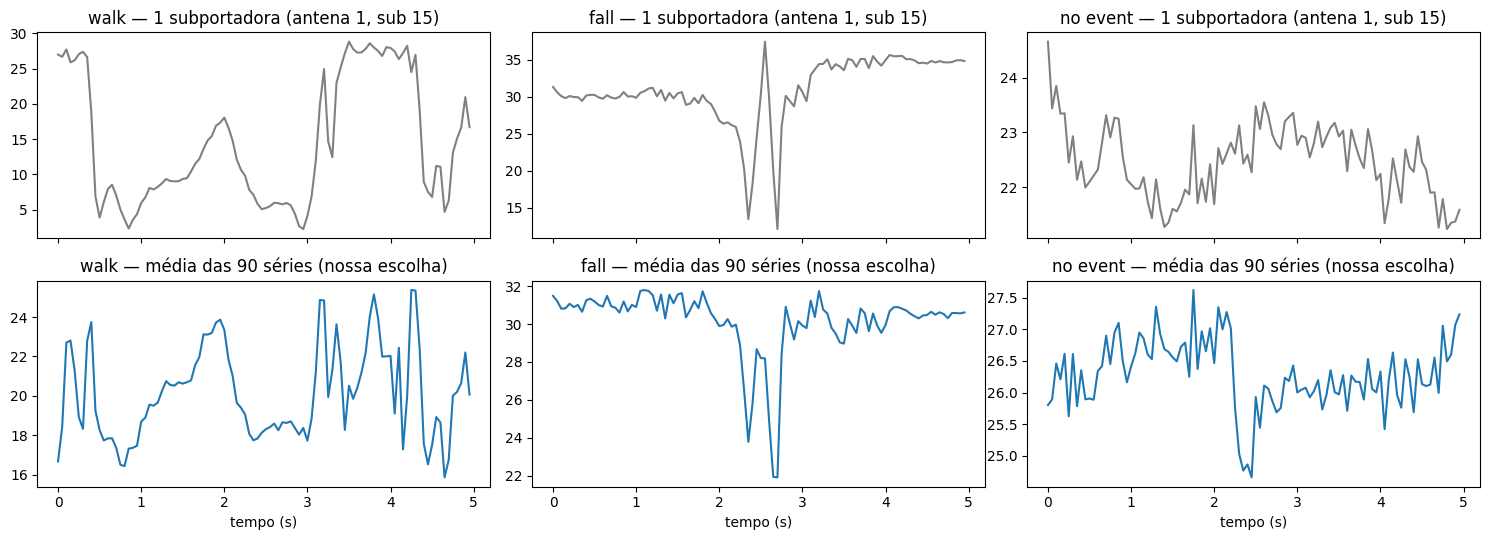

Mediana da variação (std) por classe, série média:
label
fall        1.42
no event    0.40
walk        2.30
Name: std_media, dtype: float32


In [7]:
from scipy.signal import savgol_filter

SG_JANELA, SG_ORDEM = 31, 3     # filtro Savitzky-Golay: 31 pacotes ≈ 0,1 s a 320 Hz
PASSO = 16                      # subamostragem: 1 a cada 16 → 100 pontos em 5 s (20 por segundo)

def serie_media(x90):
    return x90.astype(np.float32).mean(axis=1)

def prepara(serie):
    s = savgol_filter(serie, SG_JANELA, SG_ORDEM)
    return s[::PASSO]

S = np.stack([prepara(serie_media(X[i])) for i in range(len(X))])    # (390, 100)
print('Série final por janela:', S.shape[1], 'pontos')

SUB = 14
fig, axes = plt.subplots(2, 3, figsize=(15, 5.5), sharex=True)
t = np.arange(S.shape[1]) * PASSO / FS
for j, c in enumerate(['walk', 'fall', 'no event']):
    i = meta.index[meta.label == c][0]
    axes[0, j].plot(t, prepara(X[i, :, SUB].astype(np.float32)), color='gray')
    axes[0, j].set_title(f'{c} — 1 subportadora (antena 1, sub 15)')
    axes[1, j].plot(t, S[i], color='C0')
    axes[1, j].set_title(f'{c} — média das 90 séries (nossa escolha)')
    axes[1, j].set_xlabel('tempo (s)')
plt.tight_layout(); plt.show()

meta['std_media'] = S.std(axis=1)
print('Mediana da variação (std) por classe, série média:')
print(meta.groupby('label').std_media.median().round(2))

**O que conferir:** a linha de baixo (média) deve parecer uma versão mais limpa da de cima, com os mesmos picos. Na tabela, a ordem walk > fall > no event deve se manter, como no notebook 01.

## 3. As duas representações: texto e imagem

- **Texto:** os 100 pontos com 1 casa decimal, separados por vírgula. Algo como 400–600 tokens, o que cabe com folga em qualquer modelo. O artigo não diz quantos pontos usou: **decisão nossa, documentar**.
- **Imagem:** gráfico de linha da amplitude ao longo do tempo, **com os valores no eixo vertical**. Isso é importante: cada gráfico ajusta a escala sozinho, e sem os números um sinal quase parado pareceria tão "agitado" quanto uma caminhada.

Exemplo de texto ( walk ):
16.7, 18.4, 22.7, 22.8, 21.3, 18.9, 18.3, 22.8, 23.7, 19.2, 18.3, 17.7, 17.8, 17.8, 17.4, 16.5, 16.4, 17.3, 17.4, 17.5, 18.7, 18.9, 19.6, 19.5, 19.7, 20.2, 20.7, 20.6, 20.5, 20.7, 20.6, 20.7, 20.8, 21.6, 22.0, 23.1, 23.1, 23.2, 23.7, 23.9, 23.4, 21.8, 21.0, 19.6, 19.4, 19.1, 18.1, 17.7, 17.8, 18.1,  ...

≈ 199 tokens por série


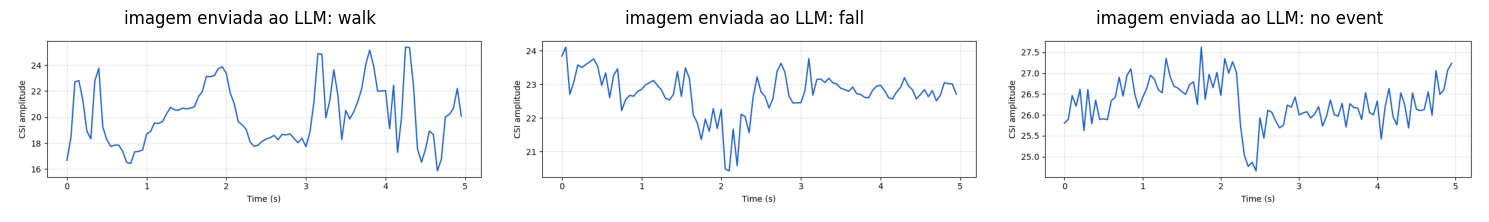

In [8]:
def para_texto(serie):
    return ', '.join(f'{v:.1f}' for v in serie)

def salva_imagem(serie, caminho):
    fig, ax = plt.subplots(figsize=(8, 3), dpi=100)
    ax.plot(np.arange(len(serie)) * PASSO / FS, serie, color='#1f5fbf', lw=1.6)
    ax.set_xlabel('Time (s)'); ax.set_ylabel('CSI amplitude')
    ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(caminho); plt.close(fig)

teste = meta[meta.split == 'test'].reset_index()      # 'index' = posição em X/S
treino = meta[meta.split == 'train'].reset_index()

for _, r in teste.iterrows():
    p = f'{IMG_DIR}/{r.id}.png'
    if not os.path.exists(p):
        salva_imagem(S[r['index']], p)

ex = teste.iloc[0]
print('Exemplo de texto (', ex.label, '):')
print(para_texto(S[ex['index']])[:300], '...')
print(f'\n≈ {len(para_texto(S[ex["index"]])) // 3} tokens por série')

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, c in zip(axes, ['walk', 'fall', 'no event']):
    r = teste[teste.label == c].iloc[0]
    ax.imshow(plt.imread(f'{IMG_DIR}/{r.id}.png')); ax.set_title(f'imagem enviada ao LLM: {c}'); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Os prompts (Apêndice A do artigo)

Usamos os textos do artigo, em inglês como no original, com **uma adaptação: 3 classes em vez de 4**. Tiramos "breath" das listas e as frases de respiração do Knowledge e do CoT, porque nosso dataset real não tem respiração. **Documentar.**

| Estratégia | O que o modelo recebe |
|---|---|
| `base` | instrução + série em texto (zero-shot) |
| `knowledge` | regras físicas de cada atividade + série |
| `cot` | roteiro de raciocínio em passos + série |
| `icl` | instrução + **3 exemplos rotulados** (1 por classe, tirados do treino) + série |
| `base_img`, `knowledge_img`, `cot_img` | os mesmos prompts + o **gráfico** da série (multimodal) |

**Exemplos do ICL:** o artigo usou 1 por classe, mas não diz como os escolheu. Pegamos, em cada classe, a janela de treino **mais típica**: aquela cuja variação está mais perto da mediana da classe. Assim evitamos sortear um caso estranho.

In [4]:
LABELS = ['fall', 'no event', 'walk']
SAIDA = 'No need to explain the reason. Output only one word as the predicted activity label: fall, no event, or walk.'

P_BASE = ('You are given a time series of Channel State Information (CSI) amplitude values captured in an environment. '
          'Your task is to classify the activity into one of the following three categories: fall, no event, or walk. '
          'The provided data represents the amplitude variations over time. Analyze the pattern and determine the most '
          'appropriate classification label based on the observed fluctuations.\n\nInput Data: {dados}\n\n' + SAIDA)

P_KNOW = ('You are an expert in Channel State Information (CSI)-based human activity recognition. CSI data reflects the '
          'changes in wireless signals as they interact with human movements. Based on CSI amplitude variations, human '
          'activities can be categorized into three types:\n'
          'Walking: Large and multiple changes in amplitude over time.\n'
          'Falling: A single significant peak or trough followed by a relatively stable period.\n'
          'No-event: The amplitude remains mostly stable with minimal fluctuations.\n\n'
          'Input Data: {dados}\n\nYour task is to classify the following CSI time series into one of these three categories.\n' + SAIDA)

P_COT = ('You are an expert in Channel State Information (CSI)-based human activity recognition. CSI data reflects the '
         'changes in wireless signals as they interact with human movements. Human bodies, being significant obstacles, '
         'cause changes in wireless signals that CSI can capture.\n'
         'You will receive time series CSI amplitude data recorded when a person is performing an activity. The person\'s '
         'activity belongs to one of the following categories: Walking, Falling, or No-event.\n'
         'Step-by-Step Analysis of Human Activity:\n'
         '- What is the variation range of the data? If the variation range is very small, does it suggest a no-event scenario?\n'
         '- Identify large peaks or troughs characterized by a significant increase or decrease, which then return to the overall range.\n'
         '- How many large peaks or troughs are present in the data?\n'
         '- If the data contains only one significant peak or trough (dramatically larger than others), does it transition into a '
         'relatively stable period with minor variations? If so, does this indicate a falling event?\n'
         '- If there are multiple large peaks and troughs occurring regularly, does this suggest a walking activity?\n'
         'Final Classification: Based on the above step-by-step analysis, determine the most appropriate classification for the '
         'given time series data.\n\nInput Data: {dados}\n\n' + SAIDA)

NOTA_IMG = '\n\nA line plot of the same time series is attached.'

# exemplos do ICL: a janela de treino mais típica de cada classe
exemplos = []
for c in LABELS:
    tr = treino[treino.label == c]
    alvo = tr.std_media.median()
    r = tr.iloc[(tr.std_media - alvo).abs().argsort().iloc[0]]
    exemplos.append((c, para_texto(S[r['index']]), r.id))
print('Exemplos do ICL:', [(c, i) for c, _, i in exemplos])

def p_icl(dados):
    cab = P_BASE.split('\n\nInput Data:')[0]
    blocos = '\n\n'.join(f'Example {k+1}:\nInput Data: {d}\nLabel: {c}' for k, (c, d, _) in enumerate(exemplos))
    return f'{cab}\n\nHere are labeled examples:\n\n{blocos}\n\nNow classify the following data.\nInput Data: {dados}\n\n{SAIDA}'

ESTRATEGIAS = {
    'base':          lambda d: P_BASE.format(dados=d),
    'knowledge':     lambda d: P_KNOW.format(dados=d),
    'cot':           lambda d: P_COT.format(dados=d),
    'icl':           p_icl,
    'base_img':      lambda d: P_BASE.format(dados=d) + NOTA_IMG,
    'knowledge_img': lambda d: P_KNOW.format(dados=d) + NOTA_IMG,
    'cot_img':       lambda d: P_COT.format(dados=d) + NOTA_IMG,
}

itens = []
for est, fn in ESTRATEGIAS.items():
    for _, r in teste.iterrows():
        itens.append(dict(id=r.id, label=r.label, estrategia=est, prompt=fn(para_texto(S[r['index']])),
                          imagem=f'imagens/{r.id}.png' if est.endswith('_img') else None))

with open(f'{OUT}/prompts_teste.jsonl', 'w') as f:
    for it in itens:
        f.write(json.dumps(it, ensure_ascii=False) + '\n')
print(f'{len(itens)} prompts salvos ({len(teste)} janelas × {len(ESTRATEGIAS)} estratégias) em nb02/prompts_teste.jsonl')
print('\n--- Exemplo: prompt "knowledge" ---\n')
print(itens[len(teste)]['prompt'][:1500], '...')

Exemplos do ICL: [('fall', 'als_0203'), ('no event', 'als_0328'), ('walk', 'als_0045')]
819 prompts salvos (117 janelas × 7 estratégias) em nb02/prompts_teste.jsonl

--- Exemplo: prompt "knowledge" ---

You are an expert in Channel State Information (CSI)-based human activity recognition. CSI data reflects the changes in wireless signals as they interact with human movements. Based on CSI amplitude variations, human activities can be categorized into three types:
Walking: Large and multiple changes in amplitude over time.
Falling: A single significant peak or trough followed by a relatively stable period.
No-event: The amplitude remains mostly stable with minimal fluctuations.

Input Data: 16.7, 18.4, 22.7, 22.8, 21.3, 18.9, 18.3, 22.8, 23.7, 19.2, 18.3, 17.7, 17.8, 17.8, 17.4, 16.5, 16.4, 17.3, 17.4, 17.5, 18.7, 18.9, 19.6, 19.5, 19.7, 20.2, 20.7, 20.6, 20.5, 20.7, 20.6, 20.7, 20.8, 21.6, 22.0, 23.1, 23.1, 23.2, 23.7, 23.9, 23.4, 21.8, 21.0, 19.6, 19.4, 19.1, 18.1, 17.7, 17.8, 18.1, 1

O arquivo `prompts_teste.jsonl` guarda **todos os prompts prontos**. Ele será reutilizado no notebook dos modelos abertos e no script do Claude Code, para que todos os modelos respondam exatamente às mesmas perguntas.

## 5. Conectar ao Gemini (gratuito)

**Uma vez só:**
1. Acesse https://aistudio.google.com/apikey com sua conta Google e clique em **Create API key**. Não precisa cadastrar cartão.
2. No Colab, clique no ícone de **chave** na barra lateral esquerda (*Secrets*), adicione um segredo com o nome `GEMINI_API_KEY`, cole a chave e ative o acesso para este notebook.

**Nunca cole a chave direto no código:** o notebook fica salvo no Drive e pode ser compartilhado.

Lembrete para o relatório: no plano gratuito, o Google pode usar os prompts para melhorar os produtos dele. Como os dados são públicos, isso não é problema aqui.

In [9]:
!pip -q install -U google-genai
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))

disponiveis = []
for m in client.models.list():
    acoes = getattr(m, 'supported_actions', None) or []
    if 'generateContent' in acoes:
        disponiveis.append(m.name.replace('models/', ''))
flash = [n for n in disponiveis if 'flash' in n and 'image' not in n and 'tts' not in n and 'live' not in n]
print('Modelos "flash" disponíveis na sua conta:'); print('  ' + '\n  '.join(flash))

MODELO = 'gemini-3.5-flash-lite'   # deixe vazio para escolher automaticamente, ou cole aqui um nome da lista acima
if not MODELO:
    estaveis = [n for n in flash if 'preview' not in n and 'exp' not in n and 'lite' not in n]
    MODELO = (estaveis or flash)[0]
print('\nModelo escolhido:', MODELO)

r = client.models.generate_content(model=MODELO, contents='Answer with one word: what color is the sky on a clear day?')
print('Teste de conexão:', r.text)

Modelos "flash" disponíveis na sua conta:
  gemini-2.5-flash
  gemini-2.5-flash-lite
  gemini-3.1-flash-lite
  gemini-3.5-flash
  gemini-3.5-flash-lite
  gemini-omni-flash-preview
  gemini-3.6-flash
  gemini-3.7-flash
  gemini-3.8-flash

Modelo escolhido: gemini-3.5-flash-lite
Teste de conexão: Blue


**Se der erro aqui:** confira o nome do segredo (`GEMINI_API_KEY`) e se o acesso ao notebook está ativado. Se o modelo escolhido der erro de cota logo no teste, cole outro nome da lista em `MODELO` e rode de novo. Os modelos "lite" costumam ter limites mais altos.

## 6. Rodar as perguntas

- **Cada resposta é salva** em `nb02/respostas_gemini.jsonl` assim que chega. Se a célula parar, por erro, limite diário ou desconexão, é só rodar de novo: o que já foi respondido é pulado.
- `PEDIDOS_POR_MINUTO` controla o ritmo. Comece com 8. Se aparecerem muitos avisos de espera, baixe para 4.
- `RODAR` define quais estratégias rodar, **na ordem**. As de texto vêm primeiro. Com 117 janelas por estratégia, as 7 somam 819 perguntas, que podem não caber no limite de um dia. Se o limite diário estourar, a célula avisa e para: continue no dia seguinte.
- **Temperatura 0**, para respostas o mais repetíveis possível (o artigo não informa a dele).

In [10]:
from tqdm.auto import tqdm

PEDIDOS_POR_MINUTO = 60
RODAR = ['base', 'knowledge', 'icl', 'cot', 'base_img', 'knowledge_img', 'cot_img']
CACHE = f'{OUT}/respostas_gemini.jsonl'

def interpreta(txt):
    t = re.sub(r'[^a-z\s-]', ' ', (txt or '').lower())
    achados = []
    for rot, padrao in [('no event', r'no[\s-]*event|none|nothing|empty'), ('fall', r'\bfall'), ('walk', r'\bwalk'), ('breath', r'\bbreath')]:
        for m in re.finditer(padrao, t):
            achados.append((m.start(), rot))
    return max(achados)[1] if achados else 'inválido'      # se houver mais de um, vale o último citado

feitos = {}
if os.path.exists(CACHE):
    with open(CACHE) as f:
        for linha in f:
            d = json.loads(linha); feitos[(d['modelo'], d['id'], d['estrategia'])] = d
print(len(feitos), 'respostas já salvas')

class LimiteDiario(Exception): pass

def pergunta(item):
    partes = []
    if item['imagem']:
        with open(f'{OUT}/{item["imagem"]}', 'rb') as f:
            partes.append(types.Part.from_bytes(data=f.read(), mime_type='image/png'))
    partes.append(item['prompt'])
    espera = 20
    for _ in range(6):
        try:
            r = client.models.generate_content(model=MODELO, contents=partes,
                                               config=types.GenerateContentConfig(temperature=0))
            return r.text or ''
        except Exception as e:
            msg = str(e)
            if 'PerDay' in msg or 'per day' in msg.lower():
                raise LimiteDiario(msg[:300])
            if any(k in msg for k in ['429', 'RESOURCE_EXHAUSTED', '503', 'UNAVAILABLE', '500']):
                print(f'  aguardando {espera}s (limite ou instabilidade)...'); time.sleep(espera); espera = min(espera * 2, 300)
                continue
            raise
    raise RuntimeError('Muitas falhas seguidas; rode a célula de novo mais tarde.')

pausa = 60 / PEDIDOS_POR_MINUTO
try:
    for est in RODAR:
        pend = [it for it in itens if it['estrategia'] == est and (MODELO, it['id'], est) not in feitos]
        for it in tqdm(pend, desc=est):
            t0 = time.time()
            resp = pergunta(it)
            d = dict(modelo=MODELO, id=it['id'], estrategia=est, label=it['label'], resposta=resp, pred=interpreta(resp))
            feitos[(MODELO, it['id'], est)] = d
            with open(CACHE, 'a') as f:
                f.write(json.dumps(d, ensure_ascii=False) + '\n')
            time.sleep(max(0, pausa - (time.time() - t0)))
    print('Todas as estratégias concluídas.')
except LimiteDiario as e:
    print('⚠ Limite diário do plano gratuito atingido. O que foi respondido está salvo.')
    print('  Rode esta célula de novo amanhã, ou troque MODELO na seção 5 e rode a partir de lá.')
    print('  Detalhe:', e)

17 respostas já salvas


base:   0%|          | 0/117 [00:00<?, ?it/s]

knowledge:   0%|          | 0/117 [00:00<?, ?it/s]

icl:   0%|          | 0/117 [00:00<?, ?it/s]

cot:   0%|          | 0/117 [00:00<?, ?it/s]

base_img:   0%|          | 0/117 [00:00<?, ?it/s]

knowledge_img:   0%|          | 0/117 [00:00<?, ?it/s]

cot_img:   0%|          | 0/117 [00:00<?, ?it/s]

Todas as estratégias concluídas.


## 7. Resultados

Para cada estratégia já respondida (completa ou não), a tabela mostra:
- **acurácia**, com o **intervalo de 95%**: a faixa onde a acurácia "verdadeira" provavelmente está, dado que o teste é pequeno;
- **F1 macro**: a média do F1 das 3 classes. Cai se o modelo ignora alguma classe;
- **inválidas**: respostas que não eram nenhum dos rótulos. Contam como erro.

**Para comparar:** chutar ao acaso dá ~33% com 3 classes. O artigo teve 62% (base), 77% (ICL) e 90% (CoT com imagem), mas com 4 classes e o GPT-4o.

Modelo: gemini-3.5-flash-lite


,estrategia,n,acuracia,ic95,f1_macro,invalidas
0,base,117,0.752,0.67–0.82,0.749,0
1,knowledge,117,0.769,0.69–0.84,0.763,0
2,cot,117,0.821,0.74–0.88,0.819,0
3,icl,117,0.812,0.73–0.87,0.806,0
4,base_img,117,0.547,0.46–0.63,0.515,0
5,knowledge_img,117,0.598,0.51–0.68,0.513,0
6,cot_img,117,0.487,0.40–0.58,0.406,0


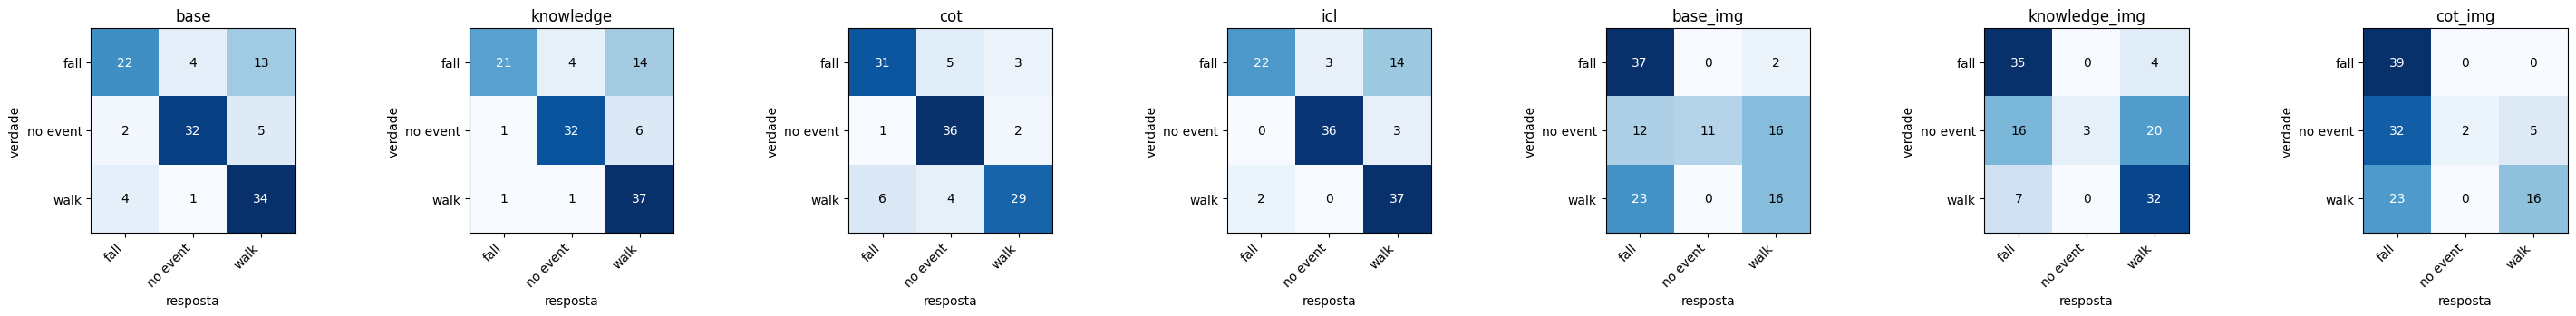

In [11]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

def wilson(acertos, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = acertos / n; den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    marg = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - marg, centro + marg

res = pd.DataFrame([d for d in feitos.values() if d['modelo'] == MODELO])
linhas = []
for est in ESTRATEGIAS:
    r = res[res.estrategia == est] if len(res) else res
    if len(r) == 0: continue
    acc = accuracy_score(r.label, r.pred)
    lo, hi = wilson((r.label == r.pred).sum(), len(r))
    linhas.append(dict(estrategia=est, n=len(r), acuracia=round(acc, 3), ic95=f'{lo:.2f}–{hi:.2f}',
                       f1_macro=round(f1_score(r.label, r.pred, labels=LABELS, average='macro', zero_division=0), 3),
                       invalidas=int((r.pred == 'inválido').sum())))
tabela = pd.DataFrame(linhas)
print('Modelo:', MODELO)
display(tabela)
tabela.to_csv(f'{OUT}/resultados_gemini_{MODELO}.csv', index=False)

ests = [e for e in ESTRATEGIAS if len(res) and (res.estrategia == e).any()]
if ests:
    cols = ['fall', 'no event', 'walk', 'breath', 'inválido']
    fig, axes = plt.subplots(1, len(ests), figsize=(4.2 * len(ests), 3.6), squeeze=False)
    for ax, est in zip(axes[0], ests):
        r = res[res.estrategia == est]
        cm = pd.crosstab(pd.Categorical(r.label, LABELS), pd.Categorical(r.pred, cols), dropna=False)
        cm = cm.loc[:, (cm.sum() > 0) | cm.columns.isin(LABELS)]
        ax.imshow(cm.values, cmap='Blues')
        ax.set_xticks(range(cm.shape[1])); ax.set_xticklabels(cm.columns, rotation=45, ha='right')
        ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
        for (a, b), v in np.ndenumerate(cm.values):
            ax.text(b, a, v, ha='center', va='center', color='white' if v > cm.values.max() / 2 else 'black')
        ax.set_title(est); ax.set_xlabel('resposta'); ax.set_ylabel('verdade')
    plt.tight_layout(); plt.show()

**Como ler a matriz de confusão:** cada linha é a classe verdadeira e cada coluna é o que o modelo respondeu. A diagonal são os acertos. Fora dela, você vê **que tipo de erro** o modelo comete: por exemplo, chamar queda de caminhada. Uma coluna `breath` indica que o modelo respondeu uma classe que nem estava nas opções.

## 8. Referência supervisionada rápida: SVM

Para ter um ponto de comparação desde já, treinamos um **SVM** (kernel RBF, como no artigo) com as 273 janelas de treino, usando as mesmas séries de 100 pontos. Os baselines completos (CNN, RNN, SVM com imagem) ficam para o notebook 04.

In [12]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

itr, ite = treino['index'].values, teste['index'].values
svm = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=SEED)).fit(S[itr], treino.label)
pred = svm.predict(S[ite])
acc = accuracy_score(teste.label, pred); lo, hi = wilson((teste.label.values == pred).sum(), len(pred))
print(f'SVM supervisionado: acurácia {acc:.3f} (IC95 {lo:.2f}–{hi:.2f}), '
      f'F1 macro {f1_score(teste.label, pred, average="macro"):.3f}')
print(pd.crosstab(teste.label, pred, rownames=['verdade'], colnames=['resposta']))

SVM supervisionado: acurácia 0.658 (IC95 0.57–0.74), F1 macro 0.665
resposta  fall  no event  walk
verdade                       
fall        26         9     4
no event    15        24     0
walk         9         3    27


## O que me mandar

1. Os gráficos da seção 2 (subportadora × média) e a mediana por classe.
2. O nome do modelo escolhido na seção 5.
3. A tabela e as matrizes de confusão da seção 7, mesmo que nem todas as estratégias tenham terminado.
4. O resultado do SVM.

Com isso comparamos com o artigo e decidimos o próximo passo: modelos abertos no Colab, Claude Code ou dados sintéticos.